# AICE 복습 실전 · 이진 분류 · 2026-11-26

**새로 만든 합성 데이터 / 창작 연습문제입니다. 공식 기출·실제 출제 보장이 아닙니다.** 전처리 복습을 충분히 하도록 24문항으로 나눴습니다. 실제 시험 문항 수를 재현한 구성은 아닙니다.

CSV와 이 노트북을 같은 폴더에 두고 위에서부터 실행하세요. 답안 셀은 비어 있으며 힌트는 접혀 있습니다. 권장 풀이: 먼저 힌트 없이 시도 → 막힌 문항만 힌트 → 정답 파일과 비교. 자동 채점기는 없습니다. 변수명·dtype·분모·반올림 위치를 지시문과 비교하세요.

필요 패키지: pandas, numpy, matplotlib, seaborn, scikit-learn, tensorflow.

## 데이터 설명
- record_id: 식별번호(학습에서 제외)
- flight_date: 일-월-연도 문자열
- time_taken: `02h 15m` 형식(시간과 분이 항상 함께 있음)
- stop: 경유 횟수와 공백·줄바꿈 뒤 설명
- ticket_price: 쉼표가 포함된 요금 문자열
- Departure Delay in Minutes: 출발 지연 시간(분)
- distance_km: 거리 / Age: 나이
- airline: 항공사 / fare_class: 좌석 등급 / route: 노선
- service_score: 서비스 점수(1~5)
- satisfaction: 정답, satisfied 또는 dissatisfied

`ticket_price`는 요금 정보입니다. 정답을 가공해 만든 피처는 없습니다.


## 01. 파일 읽기·컬럼명 변경

pandas/NumPy/matplotlib.pyplot/seaborn을 pd/np/plt/sns로 불러오세요. `01_classification.csv`를 df_original에 읽고 복사해 df에 저장하세요. `Age`를 `age`로 변경하세요. 원본 df_original은 유지하세요.

용도: rename은 컬럼 이름을 바꿉니다. 결과를 저장해야 반영됩니다.

<details><summary>힌트 보기</summary>

pd.read_csv, copy(), rename(columns={기존:새이름})

</details>

In [123]:
# [1번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_original = pd.read_csv("01_classification.csv")
df = df_original.copy()
df = df.rename(columns={
    "Age":"age"
}) 
df.head()

,record_id,flight_date,time_taken,stop,ticket_price,Departure Delay in Minutes,distance_km,age,airline,fare_class,route,service_score,satisfaction
0,1,23-12-2026,08h 59m,1-stop\n\tVia HUB,"13,977",40.93,2197.1,23,Cloud,Economy,West,4.07,dissatisfied
1,2,21-12-2026,08h 41m,1-stop\n\tVia HUB,"18,536",36.21,1682.6,29,Aero,Business,South,2.04,dissatisfied
2,3,06-02-2027,09h 24m,2+-stop\tVia HUB,"13,100",3.28,1865.3,48,Sky,Economy,West,2.24,dissatisfied
3,4,07-02-2027,04h 56m,non-stop,"19,427",2.58,1923.3,20,Cloud,Business,East,3.72,satisfied
4,5,17-12-2026,06h 02m,non-stop,"7,476",5.19,1543.2,36,Cloud,Economy,West,2.91,dissatisfied


## 02. 구조·결측치 확인

행·열 개수, 자료형, 컬럼별 결측치 수를 출력하세요. 결측치가 가장 많은 컬럼 이름을 answer02에 저장하세요.

<details><summary>힌트 보기</summary>

shape, info(), isna().sum(), idxmax()

</details>

In [124]:
# [2번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
answer02 = "service_score"

(1200, 13)
record_id                       int64
flight_date                       str
time_taken                        str
stop                              str
ticket_price                      str
Departure Delay in Minutes    float64
distance_km                   float64
age                             int64
airline                           str
fare_class                        str
route                             str
service_score                 float64
satisfaction                      str
dtype: object
record_id                      0
flight_date                    0
time_taken                     0
stop                           0
ticket_price                   0
Departure Delay in Minutes     0
distance_km                    0
age                            0
airline                        0
fare_class                     0
route                         12
service_score                 18
satisfaction                   0
dtype: int64


## 03. 문자열 안의 쉼표 제거

ticket_price의 쉼표를 지운 뒤 **정수형(int)** 으로 바꿔 같은 컬럼에 저장하세요. 중앙값을 answer03에 저장하세요.

용도: str.replace는 셀 문자열 내부를 바꿉니다. replace의 값 전체 교체와 구분하세요.

<details><summary>힌트 보기</summary>

str.replace(",", "", regex=False).astype(int)

</details>

In [125]:
# [3번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
df["ticket_price"] = df["ticket_price"].str.replace(",","").astype(int)
answer03 = df["ticket_price"].median()
answer03

np.float64(12138.0)

## 04. 특정 값의 비율

전체 행 중 `satisfaction`이 `satisfied`인 비율을 **퍼센트(0~100)** 로 구해 소수 둘째 자리까지 반올림하여 answer04에 저장하세요. 이 컬럼에는 결측치가 없습니다.

용도: value_counts(normalize=True)는 비율을 구합니다. iloc[0]은 가장 흔한 값, loc[값]은 지정한 값을 선택합니다.

<details><summary>힌트 보기</summary>

value_counts(normalize=True).loc[값] * 100 또는 (조건).mean() * 100

</details>

In [126]:
# [4번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
answer04 = round(df["satisfaction"].value_counts(normalize=True).loc["satisfied"] * 100, 2)
answer04

np.float64(35.83)

## 05. 시간 문자열을 수치로 변환

time_taken에서 시간과 분을 분리하고 **시간 + 분/60**으로 duration 컬럼을 만드세요. 개별 행은 반올림하지 마세요. duration 평균만 소수 둘째 자리까지 반올림하여 answer05에 저장하세요.

용도: str.split().str[0]은 각 문자열을 나눈 첫 조각을 꺼냅니다. 다시 df[...]로 감싸지 않습니다.

<details><summary>힌트 보기</summary>

str.split().str[0/1], str.replace(), astype(int)

</details>

In [127]:
# [5번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
hours = df["time_taken"].str.split().str[0].str.replace("h","").astype(int)
min = df["time_taken"].str.split().str[1].str.replace("m","").astype(int)/60

df["duration"] = hours + min

answer05 = round(df["duration"].mean(), 2)

## 06. 경유 정보 매핑

stop을 공백·탭·줄바꿈 기준으로 나눈 첫 조각만 사용하세요. non-stop→0, 1-stop→1, 2+-stop→2로 변환해 **정수형 stops 컬럼**에 저장하세요. stops가 1인 행 수를 answer06에 저장하세요.

용도: map은 각 값에 대응표를 적용합니다. 컬럼 전체를 if에 넣지 않습니다.

<details><summary>힌트 보기</summary>

str.split().str[0].map({...}).astype(int), (조건).sum()

</details>

In [128]:
# [6번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
stops = df["stop"].str.split().str[0]
df["stops"] = stops.map({
    "non-stop":0,
    "1-stop":1,
    "2+-stop":2
})
answer06 = df["stops"].value_counts().loc[1]
answer06

np.int64(500)

In [129]:
df

,record_id,flight_date,time_taken,stop,ticket_price,Departure Delay in Minutes,distance_km,age,airline,fare_class,route,service_score,satisfaction,duration,stops
0,1,23-12-2026,08h 59m,1-stop\n\tVia HUB,13977,40.93,2197.1,23,Cloud,Economy,West,4.07,dissatisfied,8.983333,1
1,2,21-12-2026,08h 41m,1-stop\n\tVia HUB,18536,36.21,1682.6,29,Aero,Business,South,2.04,dissatisfied,8.683333,1
2,3,06-02-2027,09h 24m,2+-stop\tVia HUB,13100,3.28,1865.3,48,Sky,Economy,West,2.24,dissatisfied,9.400000,2
3,4,07-02-2027,04h 56m,non-stop,19427,2.58,1923.3,20,Cloud,Business,East,3.72,satisfied,4.933333,0
4,5,17-12-2026,06h 02m,non-stop,7476,5.19,1543.2,36,Cloud,Economy,West,2.91,dissatisfied,6.033333,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,1196,04-12-2026,05h 03m,2+-stop\tVia HUB,14168,55.60,486.7,19,Cloud,Business,East,2.37,dissatisfied,5.050000,2
1196,1197,20-01-2027,05h 04m,non-stop,16724,49.00,1171.8,19,Cloud,Business,East,3.52,satisfied,5.066667,0
1197,1198,26-12-2026,07h 29m,1-stop\n\tVia HUB,12957,21.39,2009.3,59,Sky,Economy,North,4.60,dissatisfied,7.483333,1
1198,1199,25-01-2027,03h 17m,1-stop\n\tVia HUB,8781,21.69,1867.7,71,Sky,Economy,East,1.13,dissatisfied,3.283333,1


## 07. 날짜 차이·자료형 명시

flight_date를 format="%d-%m-%Y"로 날짜형으로 변환하세요. 2026-12-01부터 비행일까지의 **일수**를 df["days_left"]에 저장하세요. 연·월·일을 각각 flight_year, flight_month, flight_day 컬럼으로 만들고 **세 컬럼 모두 정수형(int)** 으로 저장하세요. days_left 최대값을 answer07에 저장하세요.

용도: dt.days는 날짜 차이의 일수, dt.year/month/day는 달력 성분입니다. 문자열형 날짜 조각과 숫자형 날짜 성분은 원핫 결과가 다르므로 이 문제는 정수형으로 지정합니다.

<details><summary>힌트 보기</summary>

pd.to_datetime, (날짜-기준일).dt.days, dt.year/month/day.astype(int)

</details>

In [130]:
# [7번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
df["flight_date"] = pd.to_datetime(df["flight_date"], format="%d-%m-%Y")
df["days_left"] = (df["flight_date"]-pd.to_datetime("2026-12-01")).dt.days
df["flight_year"] = df["flight_date"].dt.year
df["flight_month"] = df["flight_date"].dt.month
df["flight_day"] = df["flight_date"].dt.day
answer07 = df["days_left"].max()
answer07

np.int64(90)

## 08. 결측 행 삭제·삭제 수

df에서 결측치가 하나라도 있는 행을 삭제한 결과를 df_na에 저장하세요. 삭제된 행 수를 answer08에 저장하세요. 결측 셀 수와 삭제 행 수는 다를 수 있습니다.

<details><summary>힌트 보기</summary>

dropna(), len(df) - len(df_na)

</details>

In [131]:
# [8번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
df_na = df.copy()

df_na = df_na.dropna()

answer08 = len(df) - len(df_na)
answer08

30

## 09. 이상치 제거

df_na에서 Departure Delay in Minutes가 **300 초과**인 행을 제거해 df_del에 저장하세요. 300은 유지합니다. 삭제된 행 수를 answer09에 저장하세요. 나중에 수정할 수 있게 copy()를 사용하세요.

<details><summary>힌트 보기</summary>

조건 필터 + copy(), (조건).sum()

</details>

In [132]:
# [9번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
df_del = df_na.copy()
df_del = df_del[df_del["Departure Delay in Minutes"]<=300]
answer09 = df_na[df_na["Departure Delay in Minutes"]> 300].value_counts().sum()
answer09

np.int64(8)

## 10. 분류 정답 변환

df_del의 satisfaction을 dissatisfied→0, satisfied→1로 바꿔 **같은 컬럼에 정수형**으로 저장하세요. 변환 후 값별 개수를 출력하세요.

주의: 이 map 셀을 같은 데이터에 반복 실행하면 이미 변환된 0/1이 대응표에 없어집니다. 재실행하려면 9번부터 다시 실행하세요.

<details><summary>힌트 보기</summary>

map({...}).astype(int)

</details>

In [133]:
# [10번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
df_del["satisfaction"] = df_del["satisfaction"].map({
    "dissatisfied":0,
    "satisfied":1
})

print(df_del["satisfaction"].value_counts())

satisfaction
0    742
1    420
Name: count, dtype: int64


## 11. 상관계수의 강도

df_del의 수치형 상관계수를 구하세요(numeric_only=True). **satisfaction 자기 자신은 제외**하고 satisfaction과 상관계수 **절댓값**이 가장 큰 변수 이름을 answer11에 저장하세요.

용도: 부호는 방향, 절댓값은 선형 관계의 강도입니다. 상관관계는 인과관계 증명이 아닙니다.

<details><summary>힌트 보기</summary>

corr()[정답].drop(정답).abs().idxmax()

</details>

In [134]:
# [11번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
df_del.corr(numeric_only=True)
answer11 = "service_score"

## 12. 분포·관계 그래프

seaborn countplot으로 satisfaction별 행 개수를 그리세요. 제목은 Satisfaction Count입니다. 그래프를 출력하세요.

<details><summary>힌트 보기</summary>

sns.countplot(data=..., x=...)

</details>

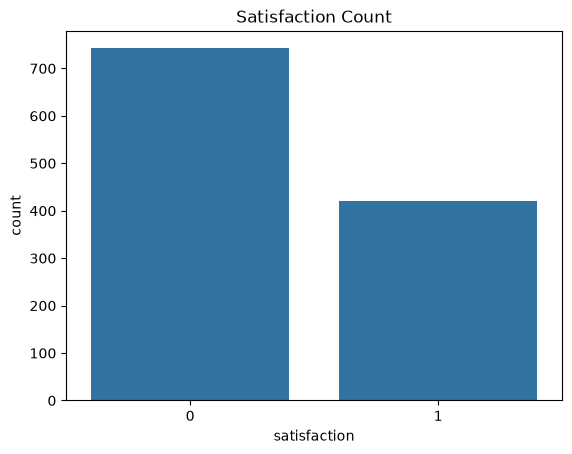

In [135]:
# [12번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
plt.figure()
sns.countplot(data=df_del, x="satisfaction")
plt.title("Satisfaction Count")
plt.show()

## 13. 불필요한 열 삭제·원핫 인코딩

df_del에서 record_id, flight_date, time_taken, stop을 삭제한 결과를 df_model에 저장하세요. 남은 object 컬럼 **airline, fare_class, route**를 모두 원핫 인코딩하여 df_preset에 저장하세요. **drop_first=False, dtype=int**를 지정하세요. 숫자형 flight_year/month/day는 인코딩하지 않습니다. df_preset의 shape와 남은 object 컬럼을 출력하세요.

<details><summary>힌트 보기</summary>

drop(columns=[...]), pd.get_dummies(columns=[...], drop_first=False, dtype=int)

</details>

In [136]:
# [13번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
df_model = df_del.copy()
df_model = df_model.drop(columns=["record_id", "flight_date", "time_taken", "stop"])

obj_cols = ["airline", "fare_class", "route"]

df_preset = df_model.copy()
df_preset = pd.get_dummies(
    df_preset,
    columns=obj_cols,
    drop_first=False,
    dtype=int
)

print(df_preset.shape)
print(df_preset.select_dtypes(include="object").columns)

(1162, 21)
Index([], dtype='str')


## 14. 학습·검증 2분할

df_preset의 satisfaction을 y, 나머지를 X에 저장하세요. train_test_split으로 test_size=0.2, random_state=42, stratify=y를 지정하세요. X_train, X_valid, y_train, y_valid에 저장하세요.

<details><summary>힌트 보기</summary>

sklearn.model_selection.train_test_split

</details>

In [137]:
# [14번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
from sklearn.model_selection import train_test_split

X = df_preset.drop(columns=["satisfaction"])
y = df_preset["satisfaction"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## 15. 스케일링·컬럼명 보존

StandardScaler를 scaler에 생성하세요. X_train_scaled는 학습 입력의 fit_transform 결과, X_valid_scaled는 검증 입력의 transform 결과입니다. **X_train/X_valid는 덮어쓰지 마세요.**

용도: 변환 결과는 보통 NumPy 배열이라 columns가 없습니다. 중요도와 연결할 변수명은 X_train.columns에 남겨둡니다.

<details><summary>힌트 보기</summary>

StandardScaler, fit_transform(train), transform(valid)

</details>

In [138]:
# [15번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)


## 16. 랜덤포레스트

RandomForestClassifier를 rf에 생성하세요. n_estimators=100, max_depth=6, random_state=42입니다. **스케일링 전** X_train, y_train으로 학습하고 X_valid 예측을 pred_rf에 저장하세요.

용도: 여러 결정트리를 종합하는 모델이며 트리 모델은 일반적으로 스케일링이 필수는 아닙니다.

<details><summary>힌트 보기</summary>

sklearn.ensemble

</details>

In [139]:
# [16번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    random_state=42
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_valid)

## 17. AdaBoost

AdaBoostClassifier를 ada에 생성하세요. n_estimators=80, learning_rate=0.5, random_state=42입니다. **스케일링 전** X_train, y_train으로 학습하고 X_valid 예측을 pred_ada에 저장하세요.

용도: 약한 모델들을 순차적으로 학습하는 부스팅입니다. 분류에서는 이전 모델이 틀린 표본에 가중치를 더 주는 방식으로 보완합니다. 회귀에서는 예측 오차를 바탕으로 표본 가중치를 조정합니다. 항상 랜덤포레스트보다 좋은 것은 아니며 같은 검증 데이터에서 비교합니다.

<details><summary>힌트 보기</summary>

sklearn.ensemble.AdaBoostClassifier

</details>

In [140]:
# [17번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(
    n_estimators=80,
    learning_rate=0.5,
    random_state=42
)

ada.fit(X_train, y_train)

pred_ada = ada.predict(X_valid)

## 18. 평가 지표 구분

각 모델의 accuracy, recall, F1, ROC-AUC를 acc_rf/recall_rf/f1_rf/auc_rf 및 acc_ada/recall_ada/f1_ada/auc_ada에 저장하고 출력하세요. 클래스 1의 확률은 proba_rf와 proba_ada에 저장하세요.

용도: accuracy와 recall 함수는 다릅니다. ROC-AUC에는 0/1 예측 대신 클래스 1의 확률을 넣으세요.

<details><summary>힌트 보기</summary>

sklearn.metrics, predict_proba()[:, 1]

</details>

In [141]:
# [18번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
from sklearn.metrics import f1_score, accuracy_score, recall_score, roc_auc_score

proba_rf = rf.predict_proba(X_valid)[:,1]
proba_ada = ada.predict_proba(X_valid)[:,1]

acc_rf = accuracy_score(y_valid, pred_rf)
recall_rf = recall_score(y_valid, pred_rf)
f1_rf = f1_score(y_valid, pred_rf)
auc_rf = roc_auc_score(y_valid, proba_rf)

acc_ada = accuracy_score(y_valid, pred_ada)
recall_ada = recall_score(y_valid, pred_ada)
f1_ada = f1_score(y_valid, pred_ada)
auc_ada = roc_auc_score(y_valid, proba_ada)

print("rf", acc_rf, recall_rf, f1_rf, auc_rf)
print("ada", acc_ada, recall_ada, f1_ada, auc_ada)


rf 0.7811158798283262 0.5238095238095238 0.6330935251798561 0.8130393096836049
ada 0.7682403433476395 0.6309523809523809 0.6625 0.8183924576542027


## 19. 변수 중요도

rf의 feature_importances_와 X_train.columns를 연결해 feature/importance 두 컬럼을 가진 fi를 만드세요. importance 내림차순 정렬 후 가장 중요한 변수 이름을 answer19에 저장하고 상위 5행을 출력하세요.

용도: 학습한 열 순서와 변수명 순서가 같아야 합니다. 배열 X_train_scaled에는 columns가 없습니다.

<details><summary>힌트 보기</summary>

pd.DataFrame({...}).sort_values(), iloc[0]["feature"]

</details>

In [ ]:
# [19번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
fi = pd.DataFrame({
    "feature":X_train.columns,
    "importance":rf.feature_importances_
}).sort_values("importance", ascending=False)

fi
answer19 = "service_score"

print(fi.head(5))

                      feature  importance
4               service_score    0.430123
1  Departure Delay in Minutes    0.102011
0                ticket_price    0.074754
2                 distance_km    0.064412
5                    duration    0.061272


## 20. 모델 비교

같은 검증 데이터에서 F1이 더 큰 모델 이름을 answer20에 저장하세요. 값은 "randomforest" 또는 "adaboost"입니다. 동점이면 randomforest를 선택하세요.

<details><summary>힌트 보기</summary>

if는 컬럼 전체가 아니라 평가 점수 하나를 비교할 때 사용합니다.

</details>

In [143]:
# [20번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
answer20 = "adaboost"

## 21. 딥러닝 모델 구성

Sequential 모델을 model에 만드세요. 첫 Dense에 input_shape=(X_train_scaled.shape[1],)를 지정하세요.
- Dense(32, relu) → Dropout(0.2) → Dense(16, relu) → Dense(1, sigmoid)
- optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"]
- y_train과 y_valid를 각각 y_train_dl/y_valid_dl에도 저장하세요. 별도의 원핫 인코딩은 하지 않습니다.

용도: 출력 1개 sigmoid는 0/1 이진 분류 확률을 출력합니다.

<details><summary>힌트 보기</summary>

Sequential, Dense, Dropout, compile()

</details>

In [144]:
# [21번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

model = Sequential([
    Dense(32, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

y_train_dl = np.asarray(y_train)
y_valid_dl = np.asarray(y_valid)


c:\Users\LSG\Desktop\AICE\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## 22. 콜백·학습

EarlyStopping을 estop에: monitor="val_loss", patience=5. ModelCheckpoint를 checkpoint에: filepath="best_01_classification.keras", monitor="val_loss", save_best_only=True. 학습은 X_train_scaled/y_train_dl, 검증은 X_valid_scaled/y_valid_dl, epochs=40, batch_size=32, callbacks=[estop, checkpoint]입니다. 학습 기록은 history에 저장하세요.

용도: EarlyStopping은 개선이 멈추면 종료하고, ModelCheckpoint는 학습 도중 가장 낮은 검증 손실의 모델을 저장합니다.

<details><summary>힌트 보기</summary>

tensorflow.keras.callbacks, model.fit()

</details>

In [145]:
# [22번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

estop = EarlyStopping(
    monitor="val_loss",
    patience=5
)

checkpoint = ModelCheckpoint(
    filepath="best_01_classification.keras",
    monitor="val_loss",
    save_best_only=True
)

history = model.fit(
    X_train_scaled,
    y_train_dl,
    epochs=40,
    batch_size=32,
    validation_data=(X_valid_scaled, y_valid_dl),
    callbacks=[estop, checkpoint]
)

Epoch 1/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5414 - loss: 0.7002 - val_accuracy: 0.6094 - val_loss: 0.6704
Epoch 2/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6416 - loss: 0.6396 - val_accuracy: 0.6395 - val_loss: 0.6333
Epoch 3/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6835 - loss: 0.6137 - val_accuracy: 0.6781 - val_loss: 0.6092
Epoch 4/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6911 - loss: 0.5910 - val_accuracy: 0.6824 - val_loss: 0.5932
Epoch 5/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7072 - loss: 0.5678 - val_accuracy: 0.6910 - val_loss: 0.5735
Epoch 6/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7212 - loss: 0.5551 - val_accuracy: 0.6824 - val_loss: 0.5602
Epoch 7/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7201 - loss: 0.5450 - val_accuracy: 0.6953 - val_loss: 0.5483
Epoch 8/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7158 - loss: 0.5477 - val_accuracy: 0.7039 - val_loss:

## 23. 저장 모델 예측·값 변환

best_01_classification.keras를 load_model로 best_model에 불러오세요. X_valid_scaled의 예측 전체를 dl_output에 저장하세요. 출력은 1열입니다. [:, 0]을 dl_proba에 저장하고 0.5 이상은 1, 미만은 0으로 변환해 dl_pred에 저장하세요. accuracy를 acc_dl에 저장하고 출력하세요. 1열에 argmax를 쓰면 모든 예측이 0이 됩니다.

<details><summary>힌트 보기</summary>

load_model, predict, [:, 0]

</details>

In [146]:
# [23번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import load_model

best_model = load_model("best_01_classification.keras")

dl_output = best_model.predict(X_valid_scaled)
dl_proba = dl_output[:,0]
dl_pred = (dl_proba>=0.5).astype(int)

acc_dl = accuracy_score(y_valid_dl, dl_pred)
print(acc_dl)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
0.7424892703862661


## 24. 학습 기록 그래프

history의 accuracy와 val_accuracy를 한 그래프에 표시하세요. 범례는 accuracy/val_accuracy, 제목은 Model ACCURACY, x축 Epoch, y축 ACCURACY입니다.

용도: history는 전체 학습 기록입니다. 마지막 epoch의 모델과 checkpoint의 최적 모델은 다를 수 있습니다.

<details><summary>힌트 보기</summary>

plt.plot(history.history[...], label=...)

</details>

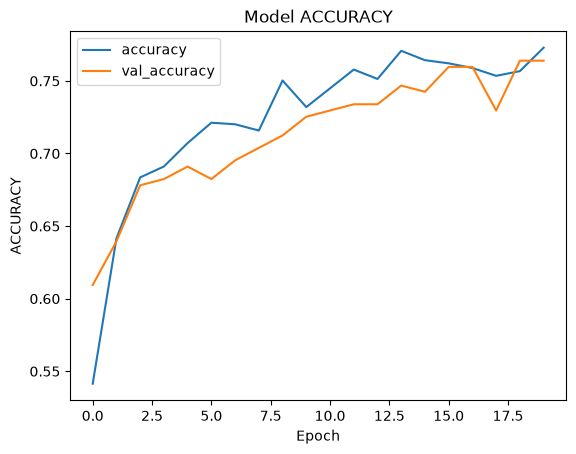

In [147]:
# [24번 문제 정답] 여기에 답안코드를 작성하고 실행하세요.
plt.plot(history.history["accuracy"], label="accuracy")
plt.plot(history.history["val_accuracy"], label="val_accuracy")

plt.legend()
plt.title("Model ACCURACY")
plt.xlabel("Epoch")
plt.ylabel("ACCURACY")
plt.show()